# Notebook 04: autoencoders and one-class deep models on KDD99

**Class 03_02.** Same protocol as notebook 02 (train on normal rows, threshold at 1% false alarms on normal
validation rows, test with 1.8% attacks), now with neural detectors in Keras 3 on the JAX backend:

| model | trained to | anomaly score |
|:--|:--|:--|
| autoencoder (AE) | reconstruct $\mathbf{x}$ through a narrow code $\mathbf{h}$ | $\lVert\mathbf{x}-\hat{\mathbf{x}}\rVert^2/d$ |
| sparse AE | same + $\lambda\lVert\mathbf{h}\rVert_1$ (few active code units) | same |
| denoising AE | reconstruct $\mathbf{x}$ from $\mathbf{x}+\boldsymbol\epsilon$ | same |
| variational AE | reconstruct + $\beta\,\mathrm{KL}(q(\mathbf{h}\mid\mathbf{x})\Vert\mathcal{N}(0,I))$ | same |
| Deep SVDD | map normal rows close to a centre $\mathbf{c}$ | $\lVert\phi(\mathbf{x})-\mathbf{c}\rVert^2$ |

A **linear** AE with a mean-squared loss learns the same subspace as PCA (Baldi and Hornik 1989): the PCA
reconstruction detector of notebook 02 is the AE's twin and its baseline.

In [1]:
import os
import sys
import time

os.environ.setdefault("KERAS_BACKEND", "jax")
import keras
import numpy as np
import polars as pl
from matplotlib import pyplot as plt

sys.path.insert(0, ".")
import plots_deep as pdp

import anomlib as an
import deeplib as dl

plt.rcParams["figure.dpi"] = 100
an.table_config()
print("Keras", keras.__version__, "backend", keras.backend.backend())
sp = an.kdd_split(seed=0)
Xtr, Xva, Xte, y = sp.X("train"), sp.X("val"), sp.X("test"), sp.y_test
cats = sp.test["category"]

Keras 3.15.1 backend jax


## A. The plain autoencoder, step by step

71 inputs $\to$ 32 (ReLU) $\to$ 8 (code) $\to$ 32 (ReLU) $\to$ 71. Trained with Adam on the mean-squared error of
*normal* rows only; 10% of them are kept aside to watch over-fitting.

Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_90 (Dense)                │ (None, 48)             │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Dense)                    │ (None, 8)              │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_91 (Dense)                │ (None, 48)             │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_92 (Dense)                │ (None, 71)             │         3,479 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,279 (90.93 KB)

 Trainable params: 7,759 (30.31 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 15,520 (60.62 KB)

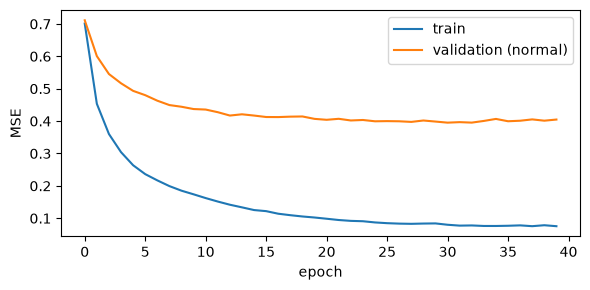

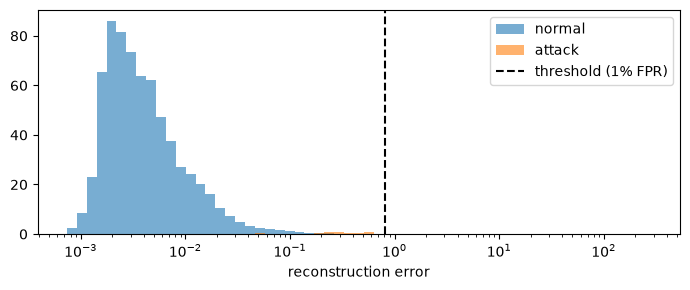

wrote assets/figures/plots/03/ae_scores.pdf


In [13]:
ae = dl.AE(latent=8, hidden=48, epochs=40, seed=42).fit(Xtr)
ae.model.summary()
h = ae.history.history
plt.figure(figsize=(6, 3))
plt.plot(h["loss"], label="train")
plt.plot(h["val_loss"], label="validation (normal)")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()
s_va, s_te = ae.score(Xva), ae.score(Xte)
t = an.threshold(s_va)
plt.figure(figsize=(7, 3))
bins = np.logspace(np.log10(s_te.min() + 1e-6), np.log10(s_te.max()), 60)
plt.hist(s_te[y == 0], bins, alpha=0.6, label="normal", density=True)
plt.hist(s_te[y == 1], bins, alpha=0.6, label="attack", density=True)
plt.axvline(t, color="k", ls="--", label="threshold (1% FPR)")
plt.xscale("log")
plt.xlabel("reconstruction error")
plt.legend()
plt.tight_layout()
plt.show()
pdp.ae_scores(s_te[y == 0], s_te[y == 1], t)  # slide plots: assets/figures/plots/03/

## B. All deep detectors against the best classic ones (3 seeds)

In [14]:
rows = []
for seed in [0, 1, 2]:
    dets = [dl.AE(latent=8, hidden=48, epochs=40, seed=seed), dl.AE(l1=1e-4, seed=seed),
    dl.AE(noise=0.1, seed=seed), dl.VAE(seed=seed),
    dl.DeepSVDD(seed=seed), an.PCARecon(), an.GMM(seed=seed)]  # fmt: skip
    for det in dets:
        t0 = time.time()
        det.fit(Xtr)
        s_va, s_te = det.score(Xva), det.score(Xte)
        rows.append({"seed": seed, "detector": det.name, **an.evaluate(s_te, y, s_va),
                     **an.recall_by_category(s_te, cats, s_va), "seconds": time.time() - t0})  # fmt: skip
deep = pl.DataFrame(rows)
cols = ["AUROC", "AUPRC", "F1", "dos", "probe", "r2l", "u2r", "seconds"]
print(deep.group_by("detector").agg([pl.col(c).mean() for c in cols] + [pl.col("AUPRC").std().alias("AUPRC std")])
      .sort("AUPRC", descending=True))  # fmt: skip
pdp.deep_band(deep.to_dicts())

┌───────────────────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬─────────┬───────────┐
│ detector              ┆ AUROC ┆ AUPRC ┆ F1    ┆ dos   ┆ probe ┆ r2l   ┆ u2r   ┆ seconds ┆ AUPRC std │
╞═══════════════════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═════════╪═══════════╡
│ autoencoder           ┆ 0.990 ┆ 0.702 ┆ 0.609 ┆ 0.987 ┆ 0.910 ┆ 0.247 ┆ 0.769 ┆ 3.241   ┆ 0.005     │
│ GMM (-log-likelihood) ┆ 0.984 ┆ 0.678 ┆ 0.620 ┆ 1.000 ┆ 0.923 ┆ 0.240 ┆ 0.731 ┆ 0.543   ┆ 0.012     │
│ Deep SVDD             ┆ 0.983 ┆ 0.613 ┆ 0.579 ┆ 0.990 ┆ 0.827 ┆ 0.200 ┆ 0.769 ┆ 1.380   ┆ 0.024     │
│ denoising AE          ┆ 0.985 ┆ 0.557 ┆ 0.572 ┆ 0.973 ┆ 0.813 ┆ 0.133 ┆ 0.769 ┆ 2.066   ┆ 0.015     │
│ PCA reconstruction    ┆ 0.982 ┆ 0.549 ┆ 0.637 ┆ 0.970 ┆ 0.880 ┆ 0.450 ┆ 0.885 ┆ 0.141   ┆ 0.000     │
│ variational AE        ┆ 0.984 ┆ 0.536 ┆ 0.579 ┆ 0.973 ┆ 0.807 ┆ 0.140 ┆ 0.769 ┆ 2.832   ┆ 0.005     │
│ sparse AE             ┆ 0.982 ┆ 0.530 ┆ 0.547 ┆ 0.970 ┆ 0.727 

**Reading.** With default sizes the deep detectors land in the same band as the classic ones: the plain AE
(AUPRC 0.55) is as good as its linear twin (PCA, 0.55), Deep SVDD is the best neural one (0.61), and the Gaussian
mixture of notebook 02 is still the best (0.68). PCA keeps the best F1 and r2l recall. This is what large benchmarks report for tabular data (ADBench, Han et al. 2022): depth is not a free lunch;
its value appears with images, sequences and very large data, where hand-made features are poor.

## C. How big should the code be?

In [15]:
rows = []
for latent in [2, 4, 8, 16, 32, 64, 128]:
    det = dl.AE(latent=latent, hidden=48, epochs=40, seed=42).fit(Xtr)
    rows.append({"code size": latent, **an.evaluate(det.score(Xte), y, det.score(Xva)),
                 "val MSE": det.history.history["val_loss"][-1]})  # fmt: skip
print(pl.DataFrame(rows))
pdp.code_size(rows, float(deep.filter(pl.col("detector").str.starts_with("GMM"))["AUPRC"].mean()))

┌───────────┬───────┬───────┬────────┬───────────┬───────┬───────┬─────────┐
│ code size ┆ AUROC ┆ AUPRC ┆ recall ┆ precision ┆ F1    ┆ FPR   ┆ val MSE │
╞═══════════╪═══════╪═══════╪════════╪═══════════╪═══════╪═══════╪═════════╡
│ 2         ┆ 0.978 ┆ 0.479 ┆ 0.555  ┆ 0.473     ┆ 0.511 ┆ 0.011 ┆ 0.818   │
│ 4         ┆ 0.985 ┆ 0.576 ┆ 0.669  ┆ 0.524     ┆ 0.588 ┆ 0.011 ┆ 0.492   │
│ 8         ┆ 0.989 ┆ 0.673 ┆ 0.699  ┆ 0.524     ┆ 0.599 ┆ 0.012 ┆ 0.405   │
│ 16        ┆ 0.991 ┆ 0.700 ┆ 0.748  ┆ 0.520     ┆ 0.614 ┆ 0.013 ┆ 0.368   │
│ 32        ┆ 0.989 ┆ 0.735 ┆ 0.816  ┆ 0.564     ┆ 0.667 ┆ 0.012 ┆ 0.329   │
│ 64        ┆ 0.987 ┆ 0.676 ┆ 0.804  ┆ 0.555     ┆ 0.657 ┆ 0.012 ┆ 0.318   │
│ 128       ┆ 0.986 ┆ 0.667 ┆ 0.788  ┆ 0.540     ┆ 0.641 ┆ 0.012 ┆ 0.349   │
└───────────┴───────┴───────┴────────┴───────────┴───────┴───────┴─────────┘
wrote assets/figures/plots/03/code_size.pdf


Too small a code (2, 4) cannot hold normal traffic, so normal rows also reconstruct badly; too large a code (128,
wider than the 71 inputs) drifts towards copying everything, attacks included. In between, a 32-unit code is the
best detector of the whole class (AUPRC 0.71, above the GMM's 0.68).

**But who chose 32?** We picked it by looking at the *test attacks*. In the one-class setting there are no labelled
attacks to tune on, and the validation MSE of normal data (last column) prefers 64, not 32. Every hyper-parameter
of an anomaly detector is a guess unless some labelled anomalies (or a realistic simulation of them) exist; a
reported gain from tuning on the test set is not a gain.

## D. Explaining an alarm: the error per feature

In [5]:
names = np.array(sp.prep.names)
err = (ae.model.predict(Xte, verbose=0) - Xte) ** 2
tops = {}
for c in an.CATEGORIES:
    e = err[(cats == c).to_numpy()].mean(0)
    top = np.argsort(e)[::-1][:4]
    tops[c] = [(names[i], float(e[i])) for i in top]
    print(f"{c:6}", ", ".join(f"{names[i]} ({e[i]:.1f})" for i in top))
pdp.explain_alarm({c: tops[c] for c in ("dos", "probe", "r2l")})

dos    dst_host_srv_serror_rate (1306.9), flag_S3 (271.1), service_telnet (100.2), dst_host_serror_rate (90.3)
probe  dst_host_srv_serror_rate (167.1), flag_RSTR (146.2), service_X11 (144.9), service_IRC (55.4)
r2l    flag_S3 (109.3), num_failed_logins (64.9), lnum_shells (61.6), lsu_attempted (36.1)
u2r    lroot_shell (828.0), lsu_attempted (384.0), lnum_shells (321.9), lnum_compromised (103.3)
wrote assets/figures/plots/03/explain_alarm.pdf


The features that the AE cannot reconstruct name the reason of the alarm (SYN-error rates for the floods, failed
logins and root shells for r2l / u2r): a first triage hint for the analyst.